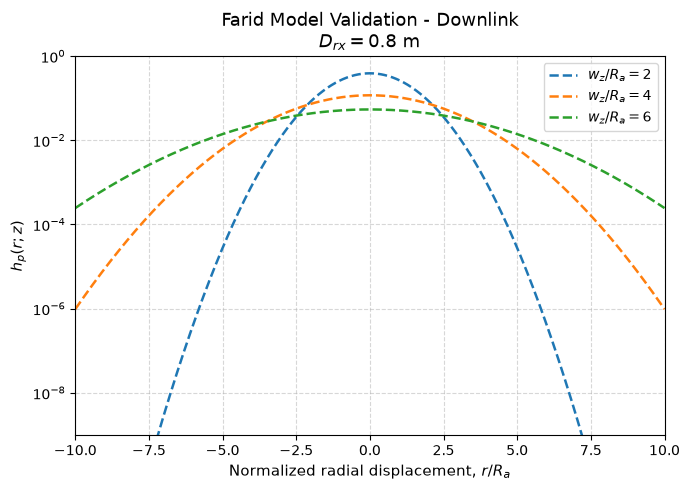

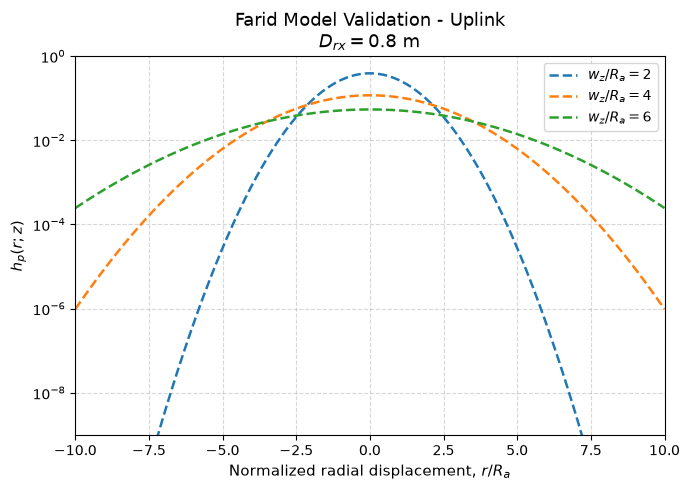

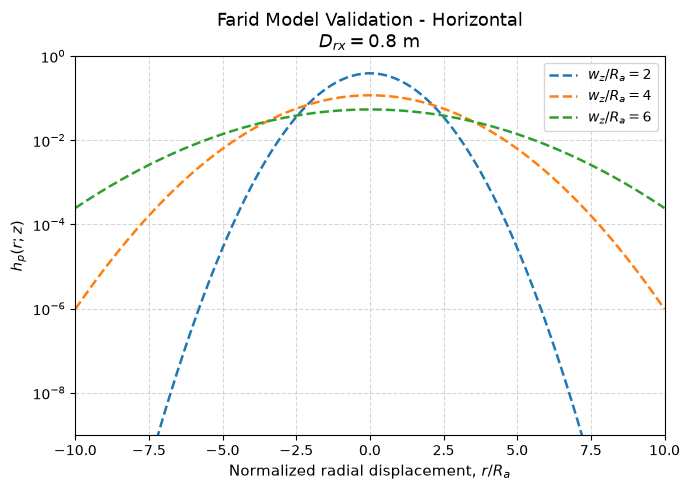

In [1]:
# Replicate figure 5 of L. Miao et al., "New Results for the Pointing Errors Model in Two Asymptotic Cases"

import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Load data
# ------------------------------------------------------------

INPUT_FILE = "qdl_fso_geometric_pointing_error_validation_1.csv"
df = pd.read_csv(INPUT_FILE)
df = df[df["type"] == "Farid"]

scenarios = df["scenario"].unique()
drx_values = sorted(df["D_rx"].unique())

# ------------------------------------------------------------
# Plot each scenario / D_rx combination
# ------------------------------------------------------------

for scenario in scenarios:
    for drx in drx_values:

        # Select one validation case
        case_df = df[
            (df["scenario"] == scenario)
            & (df["D_rx"] == drx)
        ].sort_values("x_val")

        if case_df.empty:
            continue

        # ----------------------------------------------------
        # Create figure
        # ----------------------------------------------------

        fig, ax = plt.subplots(figsize=(7, 5))

        for wst_rrx, group in case_df.groupby("WST_RRX"):
            ax.plot(
                group["x_val"],
                group["h"],
                linestyle="--",
                lw=1.8,
                label=fr"$w_z/R_a = {wst_rrx:g}$"
            )

        ax.set_yscale("log")

        ax.set_ylim(1e-9, 1.0)

        ax.set_xlim(case_df["x_val"].min(), case_df["x_val"].max())

        ax.set_title(
            f"Farid Model Validation - {scenario.capitalize()}\n"
            rf"$D_{{rx}} = {drx:g}$ m",
            fontsize=13
        )

        ax.set_xlabel(
            r"Normalized radial displacement, $r/R_a$",
            fontsize=11
        )

        ax.set_ylabel(
            r"$h_p(r;z)$",
            fontsize=11
        )

        ax.grid(
            True,
            which="both",
            linestyle="--",
            alpha=0.5
        )

        ax.legend(fontsize=10)

        plt.tight_layout()

        # plt.savefig(f"./figures/qdl_fso_geometric_pointing_error_farid_{str.lower(scenario)}.pdf")
        plt.savefig(f"./figures/qdl_fso_geometric_pointing_error_farid_{str.lower(scenario)}.png")

        plt.show()

        plt.close(fig)

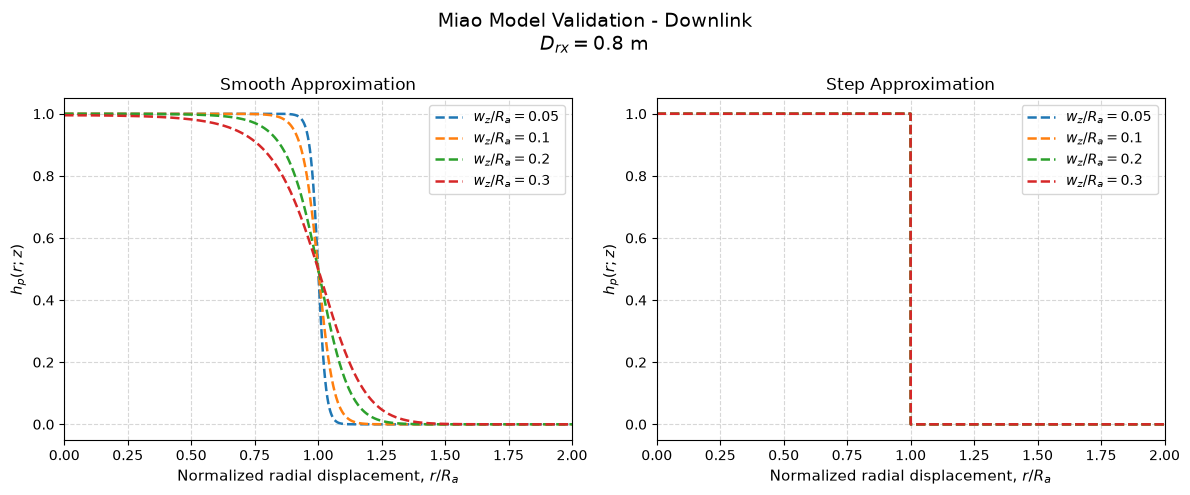

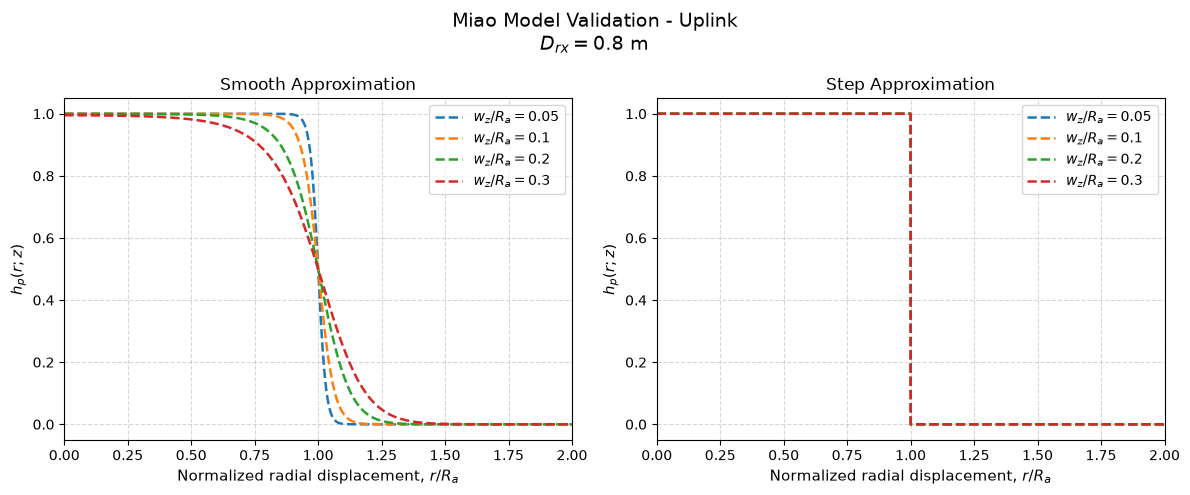

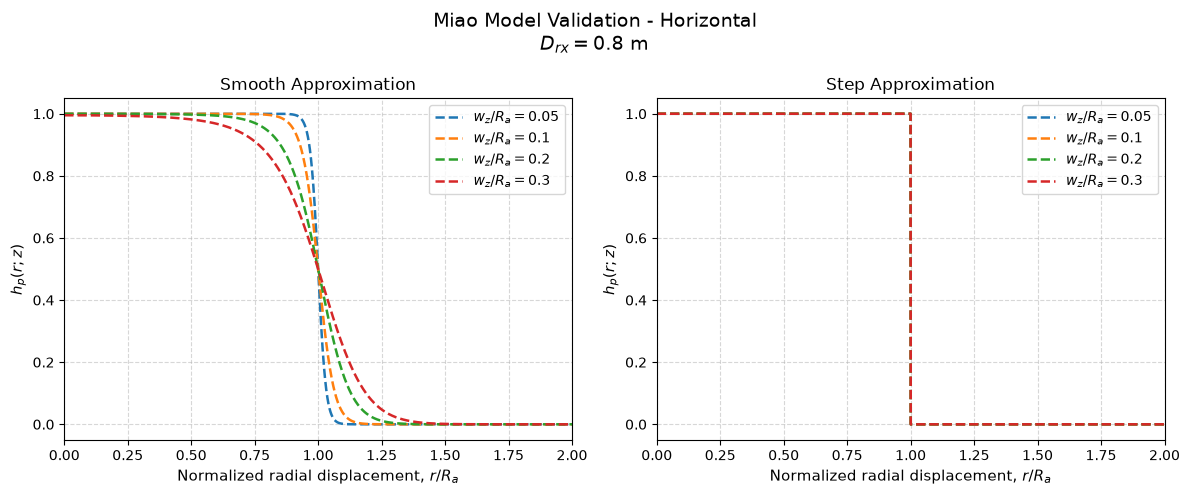

In [ ]:
# Replicate figure 8 and the step approximation of L. Miao et al., "New Results for the Pointing Errors Model in Two Asymptotic Cases"

import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Load data
# ------------------------------------------------------------

INPUT_FILE = "qdl_fso_geometric_pointing_error_validation_1.csv"
df = pd.read_csv(INPUT_FILE)
df = df[df["type"].isin(["Miao - smooth", "Miao - step"])]

scenarios = df["scenario"].unique()
drx_values = sorted(df["D_rx"].unique())


# ------------------------------------------------------------
# Plot each scenario / D_rx combination
# ------------------------------------------------------------

for scenario in scenarios:
    for drx in drx_values:

        # Select one validation case
        case_df = df[
            (df["scenario"] == scenario)
            & (df["D_rx"] == drx)
        ].sort_values("x_val")

        if case_df.empty:
            continue

        df_smooth = case_df[case_df["type"] == "Miao - smooth"]
        df_step = case_df[case_df["type"] == "Miao - step"]

        # ----------------------------------------------------
        # Create figure
        # ----------------------------------------------------

        fig, axes = plt.subplots(1, 2, figsize=(12, 5))

        fig.suptitle(
            f"Miao Model Validation - {scenario.capitalize()}\n"
            rf"$D_{{rx}} = {drx:g}$ m",
            fontsize=14
        )

        # ====================================================
        # Smooth-edge aperture
        # ====================================================

        for wst_rrx, group in df_smooth.groupby("WST_RRX"):
            axes[0].plot(
                group["x_val"],
                group["h"],
                linestyle="--",
                lw=1.8,
                label=fr"$w_z/R_a = {wst_rrx:g}$"
            )

        # axes[0].set_yscale("log")
        axes[0].set_xlim(df_smooth["x_val"].min(), df_smooth["x_val"].max())

        axes[0].set_title(
            "Smooth Approximation",
            fontsize=12
        )

        axes[0].set_xlabel(
            r"Normalized radial displacement, $r/R_a$",
            fontsize=11
        )

        axes[0].set_ylabel(
            r"$h_p(r;z)$",
            fontsize=11
        )

        axes[0].grid(
            True,
            which="both",
            linestyle="--",
            alpha=0.5
        )

        axes[0].legend(fontsize=10)

        # ====================================================
        # Step-edge aperture
        # ====================================================

        for wst_rrx, group in df_step.groupby("WST_RRX"):
            axes[1].plot(
                group["x_val"],
                group["h"],
                linestyle="--",
                lw=1.8,
                label=fr"$w_z/R_a = {wst_rrx:g}$"
            )

        # axes[1].set_yscale("log")
        axes[1].set_xlim(df_step["x_val"].min(), df_step["x_val"].max())

        axes[1].set_title(
            "Step Approximation",
            fontsize=12
        )

        axes[1].set_xlabel(
            r"Normalized radial displacement, $r/R_a$",
            fontsize=11
        )

        axes[1].set_ylabel(
            r"$h_p(r;z)$",
            fontsize=11
        )

        axes[1].grid(
            True,
            which="both",
            linestyle="--",
            alpha=0.5
        )

        axes[1].legend(fontsize=10)
        
        plt.tight_layout()

        plt.show()

        plt.close(fig)

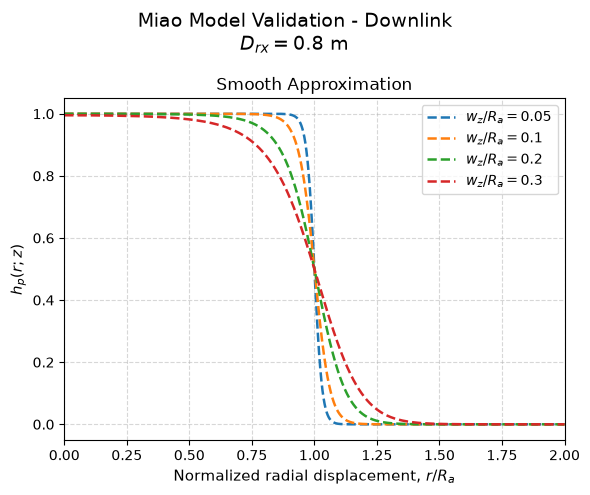

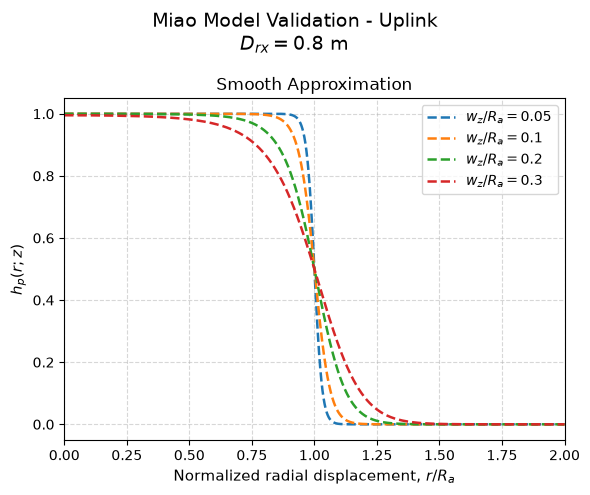

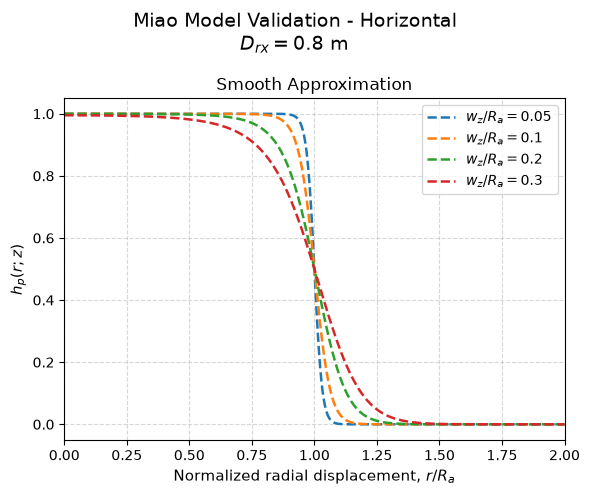

In [2]:
# Replicate Figure 8 of L. Miao et al., "New Results for the Pointing Errors Model in Two Asymptotic Cases"

import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Load data
# ------------------------------------------------------------

INPUT_FILE = "qdl_fso_geometric_pointing_error_validation_1.csv"
df = pd.read_csv(INPUT_FILE)
df = df[df["type"] == "Miao - smooth"]

scenarios = df["scenario"].unique()
drx_values = sorted(df["D_rx"].unique())

# ------------------------------------------------------------
# Plot each scenario / D_rx combination
# ------------------------------------------------------------

for scenario in scenarios:
    for drx in drx_values:

        case_df = df[
            (df["scenario"] == scenario)
            & (df["D_rx"] == drx)
        ].sort_values("x_val")

        if case_df.empty:
            continue

        # ----------------------------------------------------
        # Create figure
        # ----------------------------------------------------

        fig, ax = plt.subplots(figsize=(6, 5))

        fig.suptitle(
            f"Miao Model Validation - {scenario.capitalize()}\n"
            rf"$D_{{rx}} = {drx:g}$ m",
            fontsize=14
        )

        # ====================================================
        # Smooth-edge aperture
        # ====================================================

        for wst_rrx, group in case_df.groupby("WST_RRX"):
            ax.plot(
                group["x_val"],
                group["h"],
                linestyle="--",
                lw=1.8,
                label=fr"$w_z/R_a = {wst_rrx:g}$"
            )

        ax.set_xlim(case_df["x_val"].min(), case_df["x_val"].max())

        ax.set_title("Smooth Approximation", fontsize=12)
        ax.set_xlabel(r"Normalized radial displacement, $r/R_a$", fontsize=11)
        ax.set_ylabel(r"$h_p(r;z)$", fontsize=11)

        ax.grid(True, which="both", linestyle="--", alpha=0.5)
        ax.legend(fontsize=10)

        plt.tight_layout()

        # plt.savefig(
        #     f"./figures/qdl_fso_geometric_pointing_error_miao_{str.lower(scenario)}.pdf",
        #     bbox_inches="tight"
        # )
        plt.savefig(
            f"./figures/qdl_fso_geometric_pointing_error_miao_{str.lower(scenario)}.png",
            bbox_inches="tight"
        )

        plt.show()
        plt.close(fig)

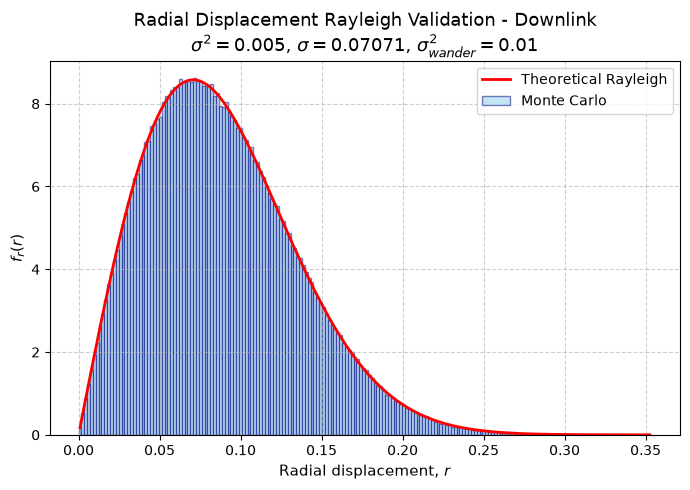

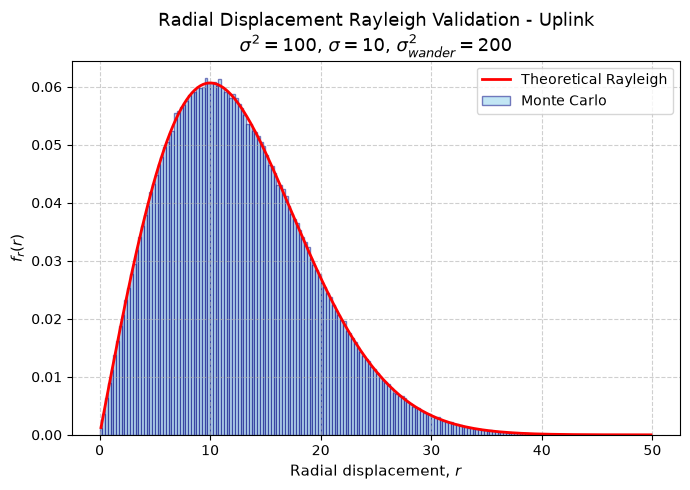

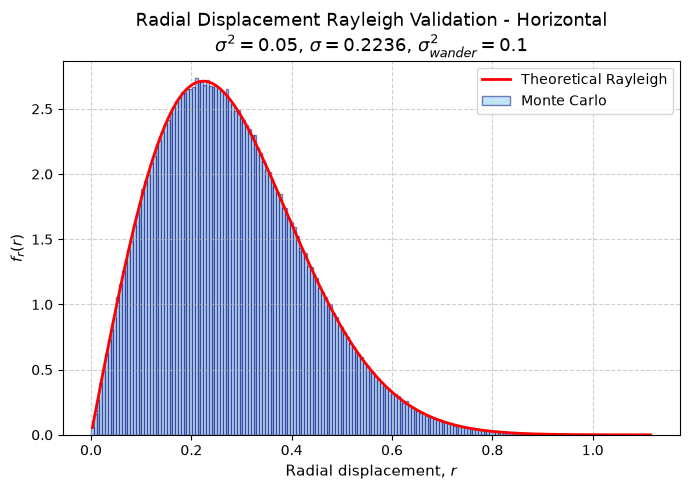

In [3]:
# Study the differences between the theoretical pdf and the empirical one

import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Load data
# ------------------------------------------------------------

INPUT_FILE = "qdl_fso_geometric_pointing_error_validation_2.csv"
df = pd.read_csv(INPUT_FILE)

scenarios = df["scenario"].unique()
wander_variances = sorted(df["wander_variance"].unique())


# ------------------------------------------------------------
# Plot each scenario / wander variance combination
# ------------------------------------------------------------

for scenario in scenarios:
    for wander_variance in wander_variances:

        # Select one validation case
        case_df = df[
            (df["scenario"] == scenario)
            & (df["wander_variance"] == wander_variance)
        ].sort_values("r")

        if case_df.empty:
            continue

        # ----------------------------------------------------
        # Create figure
        # ----------------------------------------------------

        fig, ax = plt.subplots(figsize=(7, 5))

        sigma = case_df["sigma"].iloc[0]

        # ----------------------------------------------------
        # Empirical PDF
        # ----------------------------------------------------

        if len(case_df) > 1:
            bin_width = (
                case_df["r"]
                .sort_values()
                .diff()
                .dropna()
                .mean()
            )
        else:
            bin_width = 0.1

        ax.bar(
            case_df["r"],
            case_df["mc_pdf"],
            width=bin_width,
            alpha=0.5,
            color="skyblue",
            edgecolor="navy",
            label="Monte Carlo"
        )

        # ----------------------------------------------------
        # Theoretical Rayleigh PDF
        # ----------------------------------------------------

        ax.plot(
            case_df["r"],
            case_df["theory_pdf"],
            "r-",
            lw=2,
            label=r"Theoretical Rayleigh"
        )

        # ----------------------------------------------------
        # Labels
        # ----------------------------------------------------

        ax.set_title(
            f"Radial Displacement Rayleigh Validation - "
            f"{scenario.capitalize()}\n"
            rf"$\sigma^2 = {sigma**2:.4g}$, "
            rf"$\sigma = {sigma:.4g}$, "
            rf"$\sigma_{{wander}}^2 = {wander_variance:.4g}$",
            fontsize=13
        )

        ax.set_xlabel(
            r"Radial displacement, $r$",
            fontsize=11
        )

        ax.set_ylabel(
            r"$f_r(r)$",
            fontsize=11
        )

        ax.grid(
            True,
            linestyle="--",
            alpha=0.6
        )

        ax.legend(fontsize=10)

        plt.tight_layout()

        # plt.savefig(f"./figures/qdl_fso_geometric_pointing_error_radial_rayleigh_{str.lower(scenario)}.pdf")
        plt.savefig(f"./figures/qdl_fso_geometric_pointing_error_radial_rayleigh_{str.lower(scenario)}.png")

        plt.show()

        plt.close(fig)